In [1]:
import numpy as np
import pandas as pd
import dowhy

In [7]:
from dowhy import CausalModel
import dowhy.datasets

# Set seed to enable exact replication
np.random.seed(1)

# Simulate sample data
data = dowhy.datasets.linear_dataset(
    beta=1,
    num_common_causes=2,
    num_discrete_common_causes=1,
    num_instruments=1,
    num_samples=10000,
    treatment_is_binary=True)

df = data['df']

In [8]:
# Create a causal model from the data and given graph.
model=CausalModel(
        data = df,
        treatment=data['treatment_name'],
        outcome=data['outcome_name'],
        graph=data['gml_graph']
        )

In [9]:
# Run a linear regression of column y on v0 in df
import statsmodels.api as sm

X = df['v0'].astype(float)
y = df['y'].astype(float)

X = sm.add_constant(X)

ols = sm.OLS(y, X).fit()

# Display a more parsimonious results summary
print(ols.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7966      0.017     47.194      0.000       0.764       0.830
v0             1.2947      0.022     59.804      0.000       1.252       1.337


In [10]:
# Check whether causal effect is identified and return target estimands
identified_estimand = model.identify_effect()

In [13]:
# Estimate the causal effect using inverse probability weighting
estimate = model.estimate_effect(identified_estimand,
                                 method_name="backdoor.propensity_score_weighting")

estimate

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d              
─────(E[y|W0,W1])
d[v₀]            
Estimand assumption 1, Unconfoundedness: If U→{v0} and U→y then P(y|v0,W0,W1,U) = P(y|v0,W0,W1)

## Realized estimand
b: y~v0+W0+W1
Target units: ate

## Estimate
Mean value: 1.0007774806139045

d:\conda\envs\causal\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


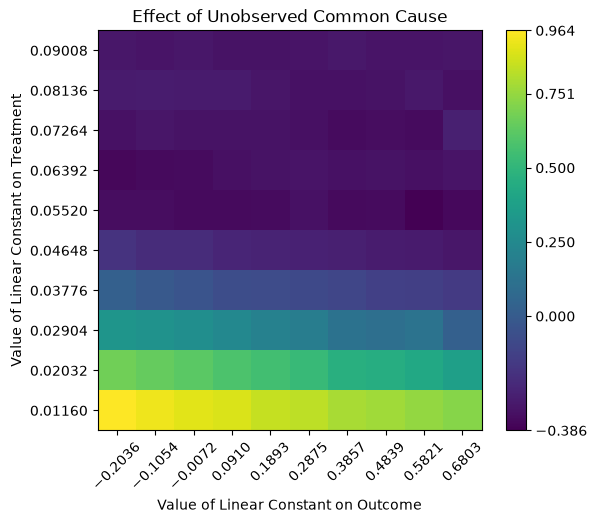

In [14]:
# Check sensitivity of obtained estimate to unobserved confounders
refute_results = model.refute_estimate(identified_estimand, estimate,
                                       method_name="add_unobserved_common_cause")